# 0 · Data preprocessing

**Run this first.** It builds the data every other notebook uses.

The client generates frames the stream never sent: **2x frame generation**. The host sends
every second frame of the display rate - 30 of 60 a second - and the client draws the one
between from the two it received last, before the next one arrives, so it adds no latency.
An example is received frames N-2 and N as the input and the unsent frame N+1 as the target.

So the clips here are at the display rate, 60 fps, and every second frame of a run is a
received one. This notebook makes those runs:

1. **Collect** sources: drawn desktop screens (`datasets/screens.py`), YouTube clips,
   photos (DIV2K) and your own screenshots in `datasets/raw/captures/`. With none of those
   on disk, it draws fake desktop screenshots instead, so the notebook always runs.
2. **Animate** each still picture as a desktop being used (`helpers/scenes.py`), at 60 fps:
   a scroll that starts and stops, a region scrolling inside a window, a window dragged, a
   menu popping up, all where a pointer moving between rests takes them. The pointer itself
   is not drawn: desktop-streamer's capture leaves it out of the video, and its client draws
   it over the picture from the position the host sends. A YouTube clip already moves, but
   only the few at 50 fps or more have a frame between every two a 30 fps stream would send.
3. **Stream** each clip the way the host does (`helpers/degrade.py`): shrink it, then
   compress it with H.264. The client works from the frames it *decoded*, and the target is a
   decoded frame too. The whole 60 fps clip is encoded and the received frames are every
   second of it - simpler than encoding the received frames alone, at the price of a codec
   that predicts over half the time a real 30 fps stream does.
4. **Cut** runs out of each clip: one spot of the screen, held still for `FRAMES_PER_RUN`
   frames from a received one, with a wide **halo** of context around it. Most of a desktop holds still, so
   most still spots are dropped, and a few runs are cut around the cursor on purpose.
5. **Save** the runs as one `.npy` array per split plus a `manifest.json` in
   `datasets/frame_gen_extra/`.

Train and validation data are split by *source* (a whole picture or a whole video), never
by run: runs of one clip overlap in time and in content, and splitting them would put
near-copies of the training data into validation.

In [1]:
"""Settings."""

from helpers import sources

CAPTURE_DIR = sources.RAW / "captures"        # your own screenshots
OUT_DIR = sources.ROOT / "frame_gen_extra"    # where the runs are written
SYNTHETIC_DIR = OUT_DIR / "synthetic"         # drawn desktop frames

SCALE = 2                  # the stream's downscale: 1280x720 on the host is 640x360 in the stream
CORE = 64                  # the spot a run is scored on, in stream pixels
HALO = 16                  # context per side; the client's tile has 4, notebooks cut down to it
FRAMES_PER_RUN = 8         # consecutive display frames per run, starting on a received one
RECEIVED_EVERY = 2         # the stream sends every 2nd display frame: 2x frame generation
RUNS_PER_SOURCE = 16       # runs cut from each source
CURSOR_RUNS = 2            # of those, cut around the cursor when the clip has one
CROP_TRIES = 8             # attempts per run before a still source gives up
VAR_MIN = 24.0             # skip runs whose brightness varies less than this (flat areas)
STILL_KEEP = 0.2           # share of the runs where nothing moves that are kept anyway
VAL_FRACTION = 0.2         # share of your own captures kept for validation
SEED = 0

# How many files of each dataset to use: "train" from its train.txt, "val" from its test.txt.
# None means every file of that split. One run is about 0.22 MB. Screens come first: a desktop
# is what the client streams. Every YouTube sequence is listed, and only those at MIN_VIDEO_FPS
# or more are used - a 30 fps video has no frame between two a 30 fps stream sends.
DATASETS = {
    "screens": {"train": None, "val": None},   # desktop screens, drawn by datasets/screens.py
    "yt8m-videos": {"train": None, "val": None},
    "div2k": {"train": 100, "val": 25},
}
MIN_VIDEO_FPS = 50

# A still picture becomes a 1 second clip of a 1280x720 window at the display rate, animated
# by helpers/scenes.py.
IMAGE_FPS = 60
CLIP_FRAMES = 60
WINDOW = (1280, 720)
# desktop-streamer's capture is told not to draw the pointer, and the client draws it itself,
# so the frames a model sees have none. True draws an arrow into them, as a capture with the
# pointer on would.
DRAW_CURSOR = False

# "stream": each source gets a random filter, bitrate and loop filter (and no codec for
# CLEAN_SHARE of them), as in ../upscale. "clean": a plain bicubic downscale, no codec.
DEGRADATION = "stream"
CLEAN_SHARE = 0.1
DEBLOCK_SHARE = 0.5

# Drawn desktop frames: only trained on when there is no other data.
SYNTHESISE_IF_EMPTY = True
SYNTHETIC_FRAMES = 12
SYNTHETIC_SIZE = (960, 600)

INPUT = CORE + 2 * HALO
assert CLIP_FRAMES >= FRAMES_PER_RUN

In [2]:
"""Imports and folders."""

import json
import subprocess
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

from helpers import degrade, runs, scenes

IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
rng = np.random.default_rng(SEED)

# how datasets/screens.py drew each screen: a "page" or a "desktop", and its display scale
SCREENS_JSON = sources.RAW / "screens" / "screens.json"
SCREENS = ({entry["file"]: entry for entry in json.loads(SCREENS_JSON.read_text(encoding="utf-8"))}
           if SCREENS_JSON.exists() else {})

CAPTURE_DIR.mkdir(parents=True, exist_ok=True)
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
print("datasets ", sources.ROOT)
print("output   ", OUT_DIR)

datasets  /home/henrik/desktop-streamer-ai/datasets
output    /home/henrik/desktop-streamer-ai/datasets/frame_gen_extra


## 1. Collect sources

Download the datasets with:

```
uv run datasets/screens.py
uv run datasets/download.py yt8m-videos --total 1000 --sequences 5
uv run datasets/download.py div2k
```

You can also put screenshots in `datasets/raw/captures/`; they are animated like the drawn
screens. A screen *recording* would be worth more than any of it - real motion, real
cursors, real menus - but there is no reader for one yet.

The drawn screens are the core of the set: text, UI edges and flat colour, which is what a
remote desktop shows, in two kinds - a tall **page** that scrolls, and a whole **desktop**
that holds still while things move on it. The YouTube clips bring real motion (including
the "Microsoft Windows" and "Website" categories, which are often screen recordings), and the
photos bring panning over natural images.

In [3]:
"""Draw a fake desktop frame: windows with title bars, text-like lines, and a noisy block."""

def synthesise_frame(size, rng):
    width, height = size
    background = tuple(int(v) for v in rng.integers(20, 60, size=3))
    frame = Image.new("RGB", size, background)
    draw = ImageDraw.Draw(frame)

    for y in range(height):  # wallpaper gradient
        shade = int(18 * y / height)
        draw.line([(0, y), (width, y)], fill=tuple(min(255, c + shade) for c in background))

    for _ in range(int(rng.integers(2, 5))):  # windows
        w = int(rng.integers(width // 4, width // 2))
        h = int(rng.integers(height // 4, height // 2))
        x = int(rng.integers(0, max(1, width - w)))
        y = int(rng.integers(0, max(1, height - h)))
        panel = tuple(int(v) for v in rng.integers(180, 250, size=3))
        accent = tuple(int(v) for v in rng.integers(40, 140, size=3))
        draw.rectangle([x, y, x + w, y + h], fill=panel, outline=accent, width=2)
        draw.rectangle([x, y, x + w, y + 22], fill=accent)  # title bar
        for i in range(3):  # window buttons
            draw.ellipse([x + w - 18 - i * 16, y + 6, x + w - 8 - i * 16, y + 16], fill=panel)

        ink = tuple(int(v) for v in rng.integers(0, 90, size=3))
        row = y + 34
        while row < y + h - 12:  # text-like lines
            length = int(rng.integers(w // 4, max(w // 4 + 1, w - 24)))
            draw.rectangle([x + 12, row, x + 12 + length, row + 4], fill=ink)
            row += int(rng.integers(10, 18))

    # a block of noise stands in for a video playing on screen
    nw, nh = width // 5, height // 5
    nx, ny = int(rng.integers(0, width - nw)), int(rng.integers(0, height - nh))
    frame.paste(Image.fromarray(rng.integers(0, 255, (nh, nw, 3), dtype=np.uint8)), (nx, ny))
    return frame

In [4]:
"""List every source: where it is, its split, and whether it is an image or a video."""


def video_fps(path, cache={}):
    """A sequence's frame rate - probed once per video, whose sequences share it."""
    folder = path.parent
    if folder not in cache:
        out = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries",
                              "stream=avg_frame_rate", "-of", "csv=p=0", str(path)],
                             capture_output=True, text=True).stdout.strip()
        numerator, _, denominator = out.partition("/")
        cache[folder] = float(numerator) / float(denominator or 1) if numerator else 0.0
    return cache[folder]


items = []
for name, wanted in DATASETS.items():
    for split, count in wanted.items():
        try:
            paths = sources.files(name, "test" if split == "val" else "train")
        except FileNotFoundError as error:
            print(f"  {name}: not on disk, skipped ({error})")
            break
        if count is not None and count < len(paths):
            paths = [paths[i] for i in sorted(rng.choice(len(paths), count, replace=False))]
        kind = "sequence" if name in sources.SEQUENCES else "image"
        if kind == "sequence":
            listed = len(paths)
            paths = [p for p in paths if video_fps(p) >= MIN_VIDEO_FPS]
            print(f"  {name} {split}: {len(paths)} of {listed} sequences at {MIN_VIDEO_FPS} fps or more")
        items += [{"dataset": name, "split": split, "path": p, "kind": kind} for p in paths]

# The drawn frames use their own random generator, so drawing them does not change any
# other random choice in this notebook.
synthetic = sorted(SYNTHETIC_DIR.glob("synthetic_*.png"))
if len(synthetic) < SYNTHETIC_FRAMES:
    synthetic_rng = np.random.default_rng(SEED)
    synthetic = [SYNTHETIC_DIR / f"synthetic_{i:04d}.png" for i in range(SYNTHETIC_FRAMES)]
    for path in synthetic:
        synthesise_frame(SYNTHETIC_SIZE, synthetic_rng).save(path)

# Your captures, split here. With no datasets and no captures, the drawn frames instead.
own = sorted(p for p in CAPTURE_DIR.rglob("*") if p.suffix.lower() in IMAGE_SUFFIXES)
label = "captures"
if not own and not items and SYNTHESISE_IF_EMPTY:
    print(f"no datasets and no captures - training on the {len(synthetic)} drawn frames")
    own, label = synthetic, "synthetic"
order = rng.permutation(len(own))
n_val = max(1, round(len(own) * VAL_FRACTION)) if len(own) > 1 else 0
held_out = {own[i] for i in order[:n_val]}
items += [{"dataset": label, "split": "val" if p in held_out else "train", "path": p, "kind": "image"}
          for p in own]

if not items:
    raise RuntimeError(f"no datasets, no images in {CAPTURE_DIR}, and synthesis is off")

for split in ("train", "val"):
    counts = {}
    for item in items:
        if item["split"] == split:
            counts[item["dataset"]] = counts.get(item["dataset"], 0) + 1
    print(f"{split:5} {sum(counts.values()):4} sources  {counts}")

  yt8m-videos train: 250 of 4444 sequences at 50 fps or more


  yt8m-videos val: 10 of 555 sequences at 50 fps or more
train  750 sources  {'screens': 400, 'yt8m-videos': 250, 'div2k': 100}
val    115 sources  {'screens': 80, 'yt8m-videos': 10, 'div2k': 25}


## 2. Animate and stream

Each source becomes a clip. A YouTube sequence already is one, at its own 50 or 60 fps. A
still picture becomes `CLIP_FRAMES` frames at `IMAGE_FPS` of a desktop being used
(`scenes.sample`), drawn from what kind of picture it is:

| kind | background | region scroll | drag | menu | cursor |
| --- | --- | --- | --- | --- | --- |
| page (a tall screen) | still, wheel, flick or steady scroll, vertical | - | 10% | 20% | 80% |
| desktop (a whole screen, your captures) | still | 40% | 35% | 30% | 90% |
| photo | still, flick or steady pan, any way | - | 10% | 10% | 50% |

The **whole frame** then goes through the stream (shrink, 4:2:0 colour, H.264, decode), not
each run on its own: a real encoder sees the whole screen, and its blocks and bitrate depend
on that. Each source gets its own random settings (`degrade.sample`), and they and the scene
are written to the manifest, so results can later be split by bitrate or by what moved. A
random run of `FRAMES_PER_RUN` frames is kept from each clip, starting on a received frame:
every `RECEIVED_EVERY`th frame of the clip from its first, so a run's frames 0, 2, 4 and 6
are received and 1, 3, 5 and 7 are the ones the client has to make.

In [5]:
"""Make one source a clip, send it through the stream, keep a run of frames."""

def degradation_for(fps):
    if DEGRADATION == "clean":
        return degrade.Degradation(scale=SCALE, filter="bicubic", bpp=None, fps=fps)
    return degrade.sample(rng, scale=SCALE, fps=fps, clean=CLEAN_SHARE, deblock=DEBLOCK_SHARE)


def screen_of(item):
    """How datasets/screens.py drew a screen, or {} for anything else."""
    if item["dataset"] != "screens":
        return {}
    return SCREENS.get(item["path"].relative_to(sources.RAW / "screens").as_posix(), {})


def kind_of(item):
    """What a source is to `scenes`: "page", "desktop" or "photo" - or "video", which is not animated."""
    if item["kind"] == "sequence":
        return "video"
    if item["dataset"] == "screens":
        return screen_of(item).get("kind", "desktop")
    return "desktop" if item["dataset"] in ("captures", "synthetic") else "photo"


def clip_of(item):
    """The decoded stream frames (FRAMES_PER_RUN, h, w, 3) of one source, the cursor's tip on
    each of them in stream pixels (None without one), and how they were made."""
    kind = kind_of(item)
    record, cursor = {"kind": kind}, None
    if kind == "video":
        frames, fps = sources.load_sequence(item["path"])
    else:
        image = sources.load_image(item["path"])
        scene = scenes.sample(rng, (image.shape[1], image.shape[0]), kind, CLIP_FRAMES, WINDOW,
                              cursor_scale=screen_of(item).get("scale"), fps=IMAGE_FPS)
        frames, fps = scenes.render(image, scene, cursor=DRAW_CURSOR), IMAGE_FPS
        record.update(events=scene.events(), scene=scene.as_dict())
        if scene.cursor is not None:
            cursor = np.array(scene.cursor) / SCALE
    if len(frames) < FRAMES_PER_RUN:
        raise ValueError(f"{item['path']}: only {len(frames)} frames")

    d = degradation_for(fps)
    _, stream = degrade.degrade(frames, d)
    # a received frame first: the stream sends frames 0, RECEIVED_EVERY, 2 * RECEIVED_EVERY...
    offset = RECEIVED_EVERY * int(rng.integers(0, (len(stream) - FRAMES_PER_RUN) // RECEIVED_EVERY + 1))
    record.update(degradation=d.as_dict(), offset=offset, fps=fps)
    keep = slice(offset, offset + FRAMES_PER_RUN)
    return stream[keep], None if cursor is None else cursor[keep], record


demo = next((item for item in items if kind_of(item) == "desktop"), items[0])
stream_demo, cursor_demo, demo_record = clip_of(demo)
print(demo["dataset"], demo["path"].name, "-", demo_record["kind"], demo_record.get("events", []))
print("stream", stream_demo.shape)
print({key: value for key, value in demo_record.items() if key != "scene"})

screens 00000.png - desktop ['drag', 'popup', 'cursor']
stream (8, 360, 640, 3)
{'kind': 'desktop', 'events': ['drag', 'popup', 'cursor'], 'degradation': {'scale': 2, 'filter': 'area', 'bpp': None, 'fps': 60, 'deblock': False}, 'offset': 12, 'fps': 60}


## 3. Cut runs

A run is one spot of the stream, held still for `FRAMES_PER_RUN` frames while the content
moves under it - exactly what one tile sees.

- The run is `INPUT` pixels: the `CORE` that is scored plus `HALO` pixels of context per
  side. The client's tile has a halo of 4; 16 are stored so a notebook can measure what
  more context is worth before anyone changes the client.
- Spots start on even pixels, because 4:2:0 colour is shared between pixel pairs.
- `CURSOR_RUNS` spots are placed around the pointer (its tip somewhere in the core on the
  run's middle frame) and kept whatever they show: it is where a window is dragged and a menu
  opens, a few pixels out of a frame of 230,000 that a random spot would almost never hold -
  whether or not the pointer is drawn (`DRAW_CURSOR`).
- Every other spot is dropped if it is flat (brightness variance under `VAR_MIN`), and
  kept if something in its core changes between two of its frames (`runs.changed_share`:
  more than `runs.MOVING_SHARE` of the core's pixels move by more than
  `runs.CHANGED_LEVEL` in luma). A spot where nothing moves is kept only `STILL_KEEP` of the
  time: repeating the last frame is already perfect there, and a whole set of them would
  teach a model nothing else.

In [6]:
"""Cut runs at random places of one clip, and around its cursor."""

LUMA = runs.LUMA


def core(run):
    return run[:, HALO:HALO + CORE, HALO:HALO + CORE]


def moves(run):
    """Whether anything in the run's core changes between two of its frames."""
    return runs.changed_share(core(run)[1:], core(run)[:-1]).max() >= runs.MOVING_SHARE


def even(value, highest):
    return int(np.clip(2 * round(value / 2), 0, highest // 2 * 2))


def crops(stream, cursor, rng):
    """[(run (T, INPUT, INPUT, 3), (y, x, tag)), ...] of one clip - tag "cursor", "moving" or
    "still" - and how many spots were skipped."""
    skipped = {"flat": 0, "still": 0}
    height, width = stream.shape[1:3]
    if height < INPUT or width < INPUT:
        return [], skipped
    spots = []
    if cursor is not None:
        # the tip somewhere in the core on the middle frame, leaving room for the arrow below it
        tip_x, tip_y = cursor[len(cursor) // 2]
        for _ in range(CURSOR_RUNS):
            y = even(tip_y - HALO - rng.uniform(4, CORE - 20), height - INPUT)
            x = even(tip_x - HALO - rng.uniform(4, CORE - 16), width - INPUT)
            spots.append((stream[:, y:y + INPUT, x:x + INPUT].copy(), (y, x, "cursor")))
    for _ in range(RUNS_PER_SOURCE * CROP_TRIES):
        if len(spots) == RUNS_PER_SOURCE:
            break
        y = 2 * int(rng.integers(0, (height - INPUT) // 2 + 1))
        x = 2 * int(rng.integers(0, (width - INPUT) // 2 + 1))
        run = stream[:, y:y + INPUT, x:x + INPUT]
        if (core(run).astype(np.float32) @ LUMA).var(axis=(1, 2)).mean() < VAR_MIN:
            skipped["flat"] += 1
            continue
        tag = "moving" if moves(run) else "still"
        if tag == "still" and rng.random() >= STILL_KEEP:
            skipped["still"] += 1
            continue
        # .copy() so a kept run does not keep the whole clip in memory
        spots.append((run.copy(), (y, x, tag)))
    return spots, skipped


spots, skipped = crops(stream_demo, cursor_demo, rng)
tags = [tag for _, (_, _, tag) in spots]
print(f"{demo['path'].name}: {len(spots)} runs kept {dict(Counter(tags))}, "
      f"spots skipped {skipped}")

00000.png: 16 runs kept {'cursor': 2, 'still': 4, 'moving': 10}, spots skipped {'flat': 0, 'still': 14}


In [7]:
"""Process every source and collect the runs per split."""

buckets = {split: {"frames": [], "files": [], "sources": []} for split in ("train", "val")}
skipped_spots = {"flat": 0, "still": 0}

start = time.time()
for n, item in enumerate(items, 1):
    bucket = buckets[item["split"]]
    stream, cursor, record = clip_of(item)
    base = {"captures": CAPTURE_DIR, "synthetic": SYNTHETIC_DIR}.get(item["dataset"], sources.RAW / item["dataset"])
    name = item["path"].relative_to(base).as_posix()
    spots, skipped = crops(stream, cursor, rng)
    for reason, count in skipped.items():
        skipped_spots[reason] += count
    if not spots:
        print(f"  skipped {item['dataset']}/{name} - too flat")
        continue
    first = len(bucket["frames"])
    bucket["frames"].extend(run for run, _ in spots)
    bucket["files"].append(f"{item['dataset']}/{name}")
    # runs [first, last) of this split came from this source, at these spots, made this way
    bucket["sources"].append({"dataset": item["dataset"], "file": name, "runs": [first, len(bucket["frames"])],
                              "spots": [list(spot) for _, spot in spots], **record})
    if n % 50 == 0:
        print(f"  {n}/{len(items)} sources, {time.time() - start:.0f}s")

for split, bucket in buckets.items():
    bucket["frames"] = (np.stack(bucket["frames"]) if bucket["frames"]
                        else np.empty((0, FRAMES_PER_RUN, INPUT, INPUT, 3), np.uint8))
    tags = [spot[2] for source in bucket["sources"] for spot in source["spots"]]
    print(f"{split:5} {len(bucket['sources']):4} sources {len(bucket['frames']):6} runs  {bucket['frames'].shape}  "
          f"{dict(Counter(tags))}")
print(f"spots skipped: {skipped_spots['flat']} flat, {skipped_spots['still']} still")
print(f"done in {time.time() - start:.1f}s")

if len(buckets["train"]["frames"]) == 0:
    raise RuntimeError("no training runs - lower VAR_MIN, or add more pictures")

  50/865 sources, 21s


  100/865 sources, 42s


  150/865 sources, 63s


  200/865 sources, 84s


  250/865 sources, 106s


...

  700/865 sources, 365s


  750/865 sources, 400s


  800/865 sources, 422s


  850/865 sources, 444s


train  748 sources  11445 runs  (11445, 8, 96, 96, 3)  {'cursor': 832, 'moving': 7224, 'still': 3389}
val    113 sources   1677 runs  (1677, 8, 96, 96, 3)  {'still': 615, 'cursor': 164, 'moving': 898}
spots skipped: 14720 flat, 16104 still
done in 451.6s


## 4. Save

One `uint8` array per split shaped `(runs, frames, height, width, 3)`, and a manifest that
describes it. Input and target are frames of the same array, so there is no second one.

In [8]:
"""Write the arrays and the manifest."""

for split, bucket in buckets.items():
    np.save(OUT_DIR / f"{split}_frames.npy", bucket["frames"])

if DEGRADATION == "clean":
    summary = "bicubic downscale + 4:2:0, no codec"
else:
    summary = (f"stream: {'/'.join(degrade.FILTERS)} downscale, 4:2:0 BT.709, H.264 libx264 CBR "
               f"at {degrade.BPP_RANGE[0]}-{degrade.BPP_RANGE[1]} bits per pixel (log-uniform), "
               f"loop filter on for {DEBLOCK_SHARE:.0%}, no codec for {CLEAN_SHARE:.0%}, per source; "
               f"images as {CLIP_FRAMES}-frame clips at {IMAGE_FPS} fps animated by helpers/scenes.py, "
               f"video at {MIN_VIDEO_FPS} fps or more; the whole clip encoded, one frame in {RECEIVED_EVERY} received")

manifest = {
    "created": time.strftime("%Y-%m-%dT%H:%M:%S"),
    "scale": SCALE,
    "core": CORE,
    "halo": HALO,
    "input": INPUT,
    "frames_per_run": FRAMES_PER_RUN,
    "received_every": RECEIVED_EVERY,   # run frames 0, 2, 4... were received; the rest are targets
    "fps": IMAGE_FPS,
    "cursor_drawn": DRAW_CURSOR,
    "runs_per_source": RUNS_PER_SOURCE,
    "cursor_runs": CURSOR_RUNS,
    "var_min": VAR_MIN,
    "still_keep": STILL_KEEP,
    "changed_level": runs.CHANGED_LEVEL,
    "moving_share": runs.MOVING_SHARE,
    "seed": SEED,
    "degradation": summary,
    "datasets": DATASETS,
    "image_clip": {"frames": CLIP_FRAMES, "fps": IMAGE_FPS, "window": list(WINDOW)},
    "splits": {
        split: {
            "runs": int(len(bucket["frames"])),
            "files": sorted(bucket["files"]),
            "frames": f"{split}_frames.npy",
            "sources": bucket["sources"],   # which runs came from which source, where, and how
        }
        for split, bucket in buckets.items()
    },
}
(OUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=1), encoding="utf-8")

written = sum(p.stat().st_size for p in OUT_DIR.glob("*.npy"))
print(f"{written / 1e6:.1f} MB written to {OUT_DIR}")

2902.4 MB written to /home/henrik/desktop-streamer-ai/datasets/frame_gen_extra


## 5. Check the result

Two things could be wrong without anything crashing. The frames of a run could be out of
order - a frame dropped or doubled by the codec round trip - and a model would learn a
motion that is not there. So we look at a few runs, and also measure it: over the runs
that move, frames one apart must be closer than frames two apart.

And the set could be mostly stillness. The histogram shows how much of the core changes
from the newest received frame N to the frame N+1 the client makes, at the frame a validation
sample uses: whatever sits at zero is a sample where repeating the last frame is already
right.

reloaded (11445, 8, 96, 96, 3) uint8


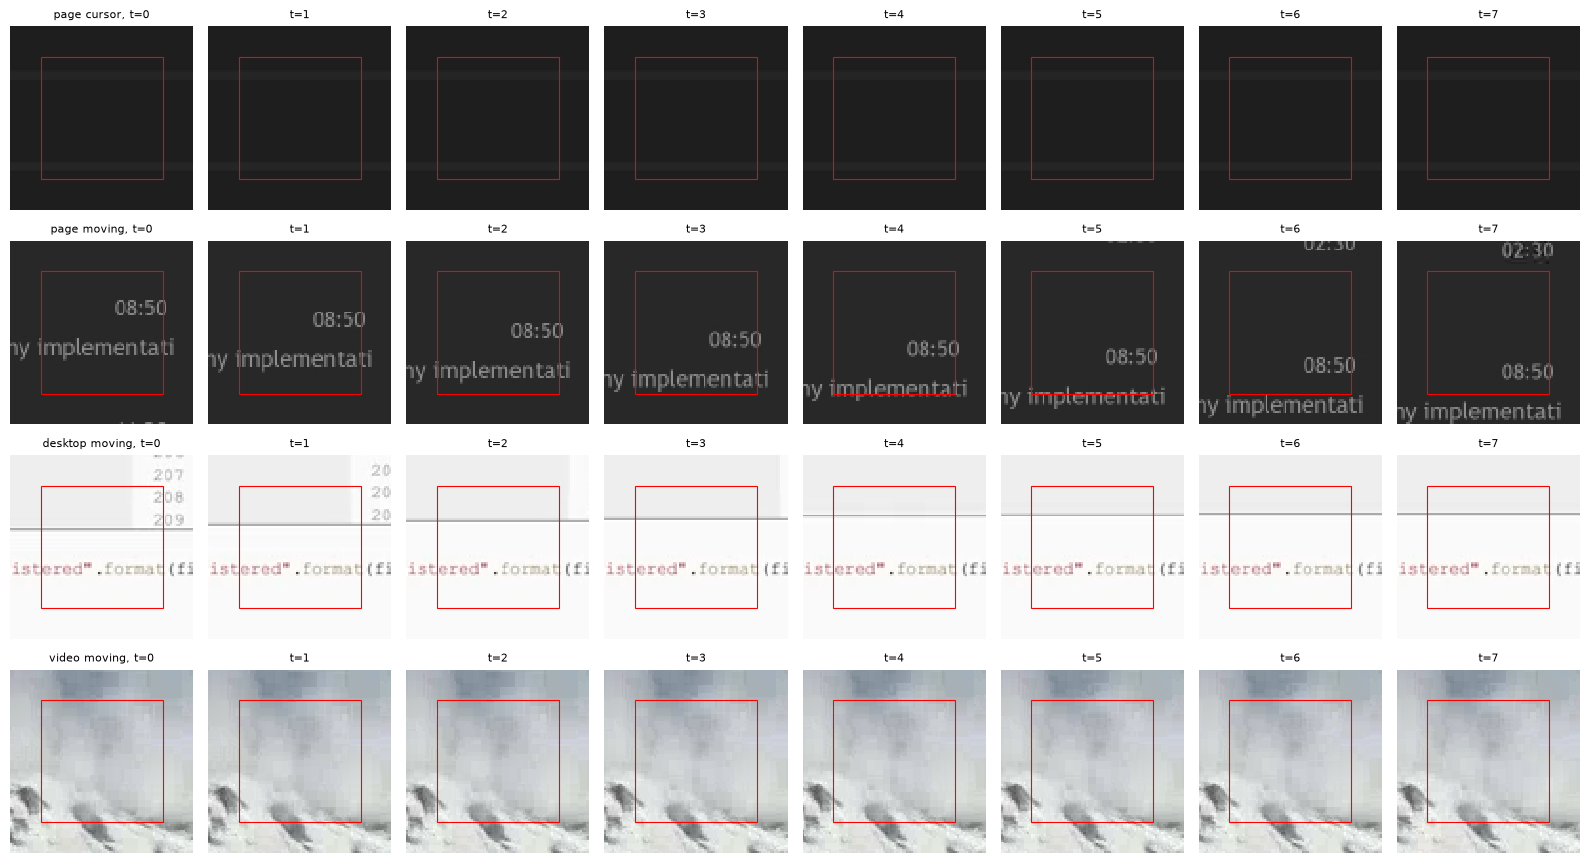

mean luma difference: 6.51 one frame apart, 9.40 two apart


In [9]:
"""Reload from disk, show a few runs, and check their frames are in order."""

manifest = json.loads((OUT_DIR / "manifest.json").read_text(encoding="utf-8"))
frames = np.load(OUT_DIR / manifest["splits"]["train"]["frames"], mmap_mode="r")
print("reloaded", frames.shape, frames.dtype)

train_sources = manifest["splits"]["train"]["sources"]
tag_of = np.array([spot[2] for source in train_sources for spot in source["spots"]])
kind_of_run = np.array([source["kind"] for source in train_sources for _ in source["spots"]])

show_rng = np.random.default_rng(SEED)
picks = [show_rng.choice(np.flatnonzero(mask)) for mask in
         (tag_of == "cursor", (tag_of == "moving") & (kind_of_run == "page"),
          (tag_of == "moving") & (kind_of_run == "desktop"), kind_of_run == "video") if mask.any()]
fig, axes = plt.subplots(len(picks), FRAMES_PER_RUN, figsize=(2 * FRAMES_PER_RUN, 2.2 * len(picks)), squeeze=False)
for row, index in enumerate(picks):
    for t in range(FRAMES_PER_RUN):
        ax = axes[row][t]
        ax.imshow(frames[index, t], interpolation="nearest")
        ax.add_patch(plt.Rectangle((HALO - 0.5, HALO - 0.5), CORE, CORE, fill=False, color="red", lw=0.8))
        ax.set_title(f"{kind_of_run[index]} {tag_of[index]}, t={t}" if t == 0 else f"t={t}", fontsize=8)
        ax.axis("off")
fig.tight_layout()
plt.show()

moving_runs = np.flatnonzero(tag_of != "still")
checked = np.sort(np.random.default_rng(SEED).choice(moving_runs, min(500, len(moving_runs)), replace=False))
sample = core(np.asarray(frames[checked]).reshape(-1, INPUT, INPUT, 3)).reshape(len(checked), FRAMES_PER_RUN, CORE, CORE, 3)
sample = sample.astype(np.float32) @ LUMA
one_apart = np.abs(sample[:, 1:] - sample[:, :-1]).mean()
two_apart = np.abs(sample[:, 2:] - sample[:, :-2]).mean()
print(f"mean luma difference: {one_apart:.2f} one frame apart, {two_apart:.2f} two apart")
assert one_apart < two_apart, "the frames of a run are not in order"

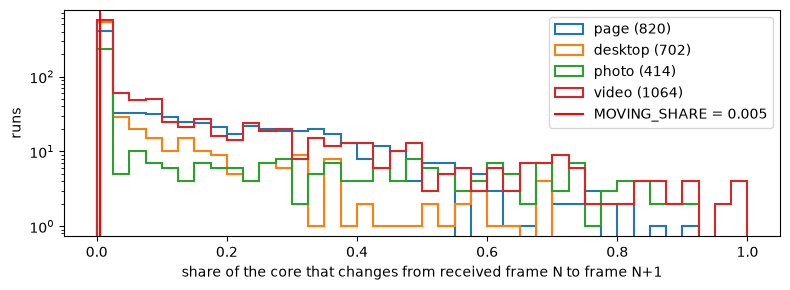

             runs  changed
page          820      54%
desktop       702      26%
photo         414      45%
video        1064      58%
events in the train clips: {'cursor': 416, 'drag': 102, 'popup': 101, 'wheel': 86, 'flick': 85, 'region': 69, 'steady': 67}
next: 01_extrapolate_dummy.ipynb


In [10]:
"""How much of each run's core changes from received frame N to the frame N+1 the client makes."""

t = runs.newest(len(frames), FRAMES_PER_RUN, 2, 1, RECEIVED_EVERY, RECEIVED_EVERY)
subset = np.sort(np.random.default_rng(SEED).choice(len(frames), min(3000, len(frames)), replace=False))
share = np.array([runs.changed_share(core(frames[i, t[i]:t[i] + 1]), core(frames[i, t[i] + 1:t[i] + 2]))[0]
                  for i in subset])

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.linspace(0, 1, 41)
for kind in ("page", "desktop", "photo", "video"):
    chosen = kind_of_run[subset] == kind
    if chosen.any():
        ax.hist(share[chosen], bins=bins, histtype="step", lw=1.5, label=f"{kind} ({chosen.sum()})")
ax.axvline(runs.MOVING_SHARE, color="red", label=f"MOVING_SHARE = {runs.MOVING_SHARE}")
ax.set_yscale("log")
ax.set_xlabel("share of the core that changes from received frame N to frame N+1")
ax.set_ylabel("runs")
ax.legend()
fig.tight_layout()
plt.show()

print(f"{'':10}{'runs':>7}{'changed':>9}")
for kind in ("page", "desktop", "photo", "video"):
    chosen = kind_of_run[subset] == kind
    if chosen.any():
        print(f"{kind:10}{chosen.sum():7}{(share[chosen] >= runs.MOVING_SHARE).mean():9.0%}")
events = {}
for source in train_sources:
    for event in source.get("events", []):
        events[event] = events.get(event, 0) + 1
print("events in the train clips:", dict(sorted(events.items(), key=lambda item: -item[1])))

print("next: 01_extrapolate_dummy.ipynb")